In [1]:

# ============================================================
# CELL 1: INSTALL REQUIRED LIBRARIES
# Project: Customer Segmentation Using Data Analysis & Clustering
# ============================================================

%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

print("All required libraries installed successfully!")


All required libraries installed successfully!


In [2]:

# ============================================================
# CELL 2: UPLOAD CUSTOMER TRANSACTION DATASET
# ============================================================

from google.colab import files
import pandas as pd
import io
from pathlib import Path

print("Please upload your Kaggle customer transaction dataset.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded. Please upload your dataset.")

# Select the uploaded file
file_name = next(iter(uploaded))
file_extension = Path(file_name).suffix.lower()

# Load the dataset based on its file format
if file_extension == ".csv":
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

elif file_extension in [".xlsx", ".xls"]:
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))

else:
    raise ValueError(
        f"Unsupported file format: {file_extension}. "
        "Please upload a CSV or Excel file."
    )

print("\nDataset uploaded successfully!")
print(f"File name: {file_name}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

display(df.head())


Please upload your Kaggle customer transaction dataset.


Saving online_retail_II.xlsx to online_retail_II.xlsx

Dataset uploaded successfully!
File name: online_retail_II.xlsx
Dataset shape: 525,461 rows × 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:

# ============================================================
# CELL 3: INITIAL DATASET INSPECTION
# Project: Customer Segmentation Using Data Analysis & Clustering
# ============================================================

import pandas as pd
import numpy as np

# 1. Dataset dimensions
print("=" * 70)
print("1. DATASET DIMENSIONS")
print("=" * 70)

rows, columns = df.shape

print(f"Number of rows       : {rows:,}")
print(f"Number of columns    : {columns:,}")
print(f"Total data cells     : {rows * columns:,}")


# 2. Column names
print("\n" + "=" * 70)
print("2. COLUMN NAMES")
print("=" * 70)

for index, column in enumerate(df.columns, start=1):
    print(f"{index:02d}. {column}")


# 3. Data types and non-null counts
print("\n" + "=" * 70)
print("3. DATAFRAME INFORMATION")
print("=" * 70)

df.info()


# 4. Detailed column summary
print("\n" + "=" * 70)
print("4. COLUMN-WISE SUMMARY")
print("=" * 70)

column_summary = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Missing Percentage": (
        df.isna().mean().values * 100
    ).round(2),
    "Unique Values": df.nunique(dropna=True).values,
    "Memory (KB)": (
        df.memory_usage(index=False, deep=True).values / 1024
    ).round(2)
})

display(column_summary)


# 5. Dataset memory usage
print("\n" + "=" * 70)
print("5. MEMORY USAGE")
print("=" * 70)

memory_bytes = df.memory_usage(index=True, deep=True).sum()

print(f"Total memory usage: {memory_bytes / 1024:.2f} KB")
print(f"Total memory usage: {memory_bytes / (1024**2):.2f} MB")


# 6. First five records
print("\n" + "=" * 70)
print("6. FIRST FIVE RECORDS")
print("=" * 70)

display(df.head())


# 7. Last five records
print("\n" + "=" * 70)
print("7. LAST FIVE RECORDS")
print("=" * 70)

display(df.tail())


# 8. Random five records
print("\n" + "=" * 70)
print("8. RANDOM FIVE RECORDS")
print("=" * 70)

display(df.sample(n=min(5, len(df)), random_state=42))


# 9. Numerical and categorical column counts
print("\n" + "=" * 70)
print("9. COLUMN TYPE DISTRIBUTION")
print("=" * 70)

print(f"Numerical columns         : {df.select_dtypes(include=np.number).shape[1]}")
print(f"Datetime columns          : {df.select_dtypes(include='datetime').shape[1]}")
print(f"Object/String columns     : {df.select_dtypes(include=['object', 'string']).shape[1]}")
print(f"Boolean columns           : {df.select_dtypes(include='bool').shape[1]}")

print("\nInitial dataset inspection completed successfully.")


1. DATASET DIMENSIONS
Number of rows       : 525,461
Number of columns    : 8
Total data cells     : 4,203,688

2. COLUMN NAMES
01. Invoice
02. StockCode
03. Description
04. Quantity
05. InvoiceDate
06. Price
07. Customer ID
08. Country

3. DATAFRAME INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

4. COLUMN-WISE SUMMARY


,Column Name,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values,Memory (KB)
0,Invoice,object,525461,0,0.00,28816,18672.63
1,StockCode,object,525461,0,0.00,4632,19952.41
2,Description,object,522533,2928,0.56,4681,38726.99
3,Quantity,int64,525461,0,0.00,825,4105.16
4,InvoiceDate,datetime64[ns],525461,0,0.00,25296,4105.16
5,Price,float64,525461,0,0.00,1606,4105.16
6,Customer ID,float64,417534,107927,20.54,4383,4105.16
7,Country,object,525461,0,0.00,40,32047.09



5. MEMORY USAGE
Total memory usage: 125819.91 KB
Total memory usage: 122.87 MB

6. FIRST FIVE RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



7. LAST FIVE RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525460,538171,21931,JUMBO STORAGE BAG SUKI,2,2010-12-09 20:01:00,1.95,17530.0,United Kingdom



8. RANDOM FIVE RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
391453,527050,20750,RED RETROSPOT MINI CASES,6,2010-10-14 12:54:00,7.95,17717.0,United Kingdom
440086,531382,82583,HOT BATHS METAL SIGN,3,2010-11-07 16:29:00,2.10,16549.0,United Kingdom
369036,525059,22951,72 CAKE CASES DOLLY GIRL DESIGN,48,2010-10-03 14:08:00,0.55,15978.0,United Kingdom
232578,511928,21915,RED HARMONICA IN BOX,12,2010-06-11 11:45:00,1.25,15141.0,United Kingdom
41357,492792,22311,OFFICE MUG WARMER BLACK+SILVER,12,2009-12-20 10:08:00,4.95,17243.0,United Kingdom



9. COLUMN TYPE DISTRIBUTION
Numerical columns         : 3
Datetime columns          : 1
Object/String columns     : 4
Boolean columns           : 0

Initial dataset inspection completed successfully.


In [4]:

# ============================================================
# CELL 4: DATA QUALITY ASSESSMENT
# Purpose: Identify issues before cleaning the dataset
# IMPORTANT: This cell does not modify the original dataframe.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. MISSING VALUES
# ------------------------------------------------------------
print("=" * 75)
print("1. MISSING VALUE ANALYSIS")
print("=" * 75)

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Non-Missing Count": df.notnull().sum()
}).sort_values("Missing Count", ascending=False)

display(missing_summary)


# ------------------------------------------------------------
# 2. EXACT DUPLICATE ROWS
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("2. DUPLICATE RECORD ANALYSIS")
print("=" * 75)

duplicate_count = df.duplicated().sum()

print(f"Exact duplicate rows       : {duplicate_count:,}")
print(f"Percentage of dataset      : {duplicate_count / len(df) * 100:.2f}%")

if duplicate_count > 0:
    print("\nSample duplicate records:")
    display(df[df.duplicated(keep=False)].head(10))


# ------------------------------------------------------------
# 3. NUMERICAL VALUE CHECKS
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("3. NUMERICAL VALUE ANALYSIS")
print("=" * 75)

numeric_columns = ["Quantity", "Price"]

for col in numeric_columns:
    print(f"\n--- {col} ---")
    print(f"Minimum        : {df[col].min()}")
    print(f"Maximum        : {df[col].max()}")
    print(f"Mean           : {df[col].mean():.2f}")
    print(f"Median         : {df[col].median():.2f}")
    print(f"Zero values    : {(df[col] == 0).sum():,}")
    print(f"Negative values: {(df[col] < 0).sum():,}")

    display(df[col].describe().to_frame().T)


# ------------------------------------------------------------
# 4. CUSTOMER ID VALIDATION
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("4. CUSTOMER ID ANALYSIS")
print("=" * 75)

customer_col = "Customer ID"

print(f"Missing Customer IDs        : {df[customer_col].isna().sum():,}")
print(f"Unique identified customers : {df[customer_col].nunique():,}")

# Check whether non-missing IDs are integer-like
valid_customer_ids = df[customer_col].dropna()

non_integer_ids = (
    valid_customer_ids % 1 != 0
).sum()

print(f"Non-integer Customer IDs    : {non_integer_ids:,}")


# ------------------------------------------------------------
# 5. INVOICE VALIDATION
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("5. INVOICE ANALYSIS")
print("=" * 75)

invoice_strings = df["Invoice"].astype("string").str.strip()

print(f"Unique invoices              : {df['Invoice'].nunique():,}")
print(f"Blank invoice values         : {invoice_strings.eq('').sum():,}")
print(f"Invoices starting with 'C'   : {invoice_strings.str.upper().str.startswith('C', na=False).sum():,}")

print("\nSample invoices starting with 'C':")
display(df.loc[
    invoice_strings.str.upper().str.startswith("C", na=False),
    ["Invoice", "StockCode", "Quantity", "Price", "Customer ID"]
].head(10))


# ------------------------------------------------------------
# 6. DATE VALIDATION
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("6. TRANSACTION DATE ANALYSIS")
print("=" * 75)

print(f"Earliest transaction : {df['InvoiceDate'].min()}")
print(f"Latest transaction   : {df['InvoiceDate'].max()}")
print(f"Missing dates        : {df['InvoiceDate'].isna().sum():,}")
print(f"Invalid date dtype   : {not pd.api.types.is_datetime64_any_dtype(df['InvoiceDate'])}")

print("\nTransactions by year:")
display(df["InvoiceDate"].dt.year.value_counts().sort_index().to_frame("Transaction Rows"))


# ------------------------------------------------------------
# 7. PRODUCT DESCRIPTION VALIDATION
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("7. PRODUCT DESCRIPTION ANALYSIS")
print("=" * 75)

description = df["Description"].astype("string")

print(f"Missing descriptions       : {df['Description'].isna().sum():,}")
print(f"Blank descriptions         : {description.str.strip().eq('').sum():,}")
print(f"Unique descriptions        : {df['Description'].nunique():,}")

print("\nSample rows with missing or blank descriptions:")
display(df.loc[
    df["Description"].isna() | description.str.strip().eq(""),
    ["Invoice", "StockCode", "Description", "Quantity", "Price"]
].head(10))


# ------------------------------------------------------------
# 8. CATEGORICAL TEXT CONSISTENCY
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("8. TEXT CONSISTENCY CHECK")
print("=" * 75)

for col in ["StockCode", "Country"]:
    text_values = df[col].astype("string")

    blank_count = text_values.str.strip().eq("").sum()
    whitespace_count = (
        text_values.notna() &
        text_values.ne(text_values.str.strip())
    ).sum()

    print(f"\n{col}")
    print(f"Blank values               : {blank_count:,}")
    print(f"Leading/trailing whitespace: {whitespace_count:,}")
    print(f"Unique values               : {df[col].nunique():,}")


# ------------------------------------------------------------
# 9. PRELIMINARY TRANSACTION VALUE CHECK
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("9. TRANSACTION VALUE ANALYSIS")
print("=" * 75)

# Diagnostic only; no rows are removed.
transaction_value = df["Quantity"] * df["Price"]

print(f"Negative transaction values : {(transaction_value < 0).sum():,}")
print(f"Zero transaction values     : {(transaction_value == 0).sum():,}")
print(f"Positive transaction values : {(transaction_value > 0).sum():,}")

print("\nTransaction value statistics:")
display(transaction_value.describe().to_frame("Transaction Value"))


# ------------------------------------------------------------
# 10. POTENTIAL OUTLIERS (IQR DIAGNOSTIC)
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("10. POTENTIAL NUMERICAL OUTLIERS")
print("=" * 75)

for col in ["Quantity", "Price"]:
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (series < lower_bound) | (series > upper_bound)

    print(f"\n{col}")
    print(f"Q1                  : {q1:.2f}")
    print(f"Q3                  : {q3:.2f}")
    print(f"IQR                 : {iqr:.2f}")
    print(f"Lower bound         : {lower_bound:.2f}")
    print(f"Upper bound         : {upper_bound:.2f}")
    print(f"Potential outliers  : {outlier_mask.sum():,}")

print("\nData quality assessment completed.")
print("Original dataframe remains unchanged.")


1. MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage,Non-Missing Count
Customer ID,107927,20.54,417534
Description,2928,0.56,522533
StockCode,0,0.00,525461
Invoice,0,0.00,525461
Quantity,0,0.00,525461
InvoiceDate,0,0.00,525461
Price,0,0.00,525461
Country,0,0.00,525461



2. DUPLICATE RECORD ANALYSIS
Exact duplicate rows       : 6,865
Percentage of dataset      : 1.31%

Sample duplicate records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom



3. NUMERICAL VALUE ANALYSIS

--- Quantity ---
Minimum        : -9600
Maximum        : 19152
Mean           : 10.34
Median         : 3.00
Zero values    : 0
Negative values: 12,326


...


7. PRODUCT DESCRIPTION ANALYSIS
Missing descriptions       : 2,928
Blank descriptions         : 0
Unique descriptions        : 4,681

Sample rows with missing or blank descriptions:


,Invoice,StockCode,Description,Quantity,Price
470,489521,21646,NaN,-50,0.0
3114,489655,20683,NaN,-44,0.0
3161,489659,21350,NaN,230,0.0
3731,489781,84292,NaN,17,0.0
4296,489806,18010,NaN,-770,0.0
4566,489821,85049G,NaN,-240,0.0
6378,489882,35751C,NaN,12,0.0
6555,489898,79323G,NaN,954,0.0
6576,489901,21098,NaN,-200,0.0
6581,489903,21166,NaN,48,0.0



8. TEXT CONSISTENCY CHECK

StockCode
Blank values               : 0
Leading/trailing whitespace: 1
Unique values               : 4,632

Country
Blank values               : 0
Leading/trailing whitespace: 0
Unique values               : 40

9. TRANSACTION VALUE ANALYSIS
Negative transaction values : 10,208
Zero transaction values     : 3,687
Positive transaction values : 511,566

Transaction value statistics:


,Transaction Value
count,525461.000000
mean,18.154506
std,160.333083
min,-53594.360000
25%,3.750000
50%,9.950000
75%,17.700000
max,25111.090000



10. POTENTIAL NUMERICAL OUTLIERS

Quantity
Q1                  : 1.00
Q3                  : 10.00
IQR                 : 9.00
Lower bound         : -12.50
Upper bound         : 23.50
Potential outliers  : 57,870

Price
Q1                  : 1.25
Q3                  : 4.21
IQR                 : 2.96
Lower bound         : -3.19
Upper bound         : 8.65
Potential outliers  : 35,273

Data quality assessment completed.
Original dataframe remains unchanged.


In [5]:

# ============================================================
# CELL 5: DATA CLEANING AND PREPROCESSING
# Project: Customer Segmentation Using Data Analysis & Clustering
# Original dataframe (df) remains unchanged.
# ============================================================

import pandas as pd
import numpy as np

# Create a separate working copy
df_clean = df.copy()

# Track dataset size after every cleaning operation
cleaning_log = []

def record_step(step_name, data):
    cleaning_log.append({
        "Cleaning Step": step_name,
        "Rows Remaining": len(data),
        "Rows Removed": (
            cleaning_log[-1]["Rows Remaining"] - len(data)
            if cleaning_log else len(df) - len(data)
        )
    })

print("=" * 75)
print("STARTING DATA CLEANING")
print("=" * 75)

record_step("Original dataset", df_clean)
print(f"Original rows: {len(df_clean):,}")


# ------------------------------------------------------------
# 1. REMOVE EXACT DUPLICATE RECORDS
# ------------------------------------------------------------
before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

record_step("Removed exact duplicates", df_clean)

print(f"\n1. Duplicate rows removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 2. REMOVE ROWS WITHOUT CUSTOMER IDs
# Customer IDs cannot be meaningfully mean-imputed.
# ------------------------------------------------------------
before = len(df_clean)

df_clean = df_clean.dropna(subset=["Customer ID"]).copy()

record_step("Removed missing Customer IDs", df_clean)

print(f"2. Rows without Customer ID removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 3. REMOVE MISSING PRODUCT DESCRIPTIONS
# Following the chosen policy for missing string values.
# ------------------------------------------------------------
before = len(df_clean)

df_clean = df_clean.dropna(subset=["Description"]).copy()

record_step("Removed missing descriptions", df_clean)

print(f"3. Rows with missing descriptions removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 4. STANDARDIZE TEXT FIELDS
# ------------------------------------------------------------
for col in ["Invoice", "StockCode", "Description", "Country"]:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Remove rows with blank essential text fields
before = len(df_clean)

df_clean = df_clean[
    df_clean["Invoice"].notna()
    & df_clean["Invoice"].ne("")
    & df_clean["StockCode"].notna()
    & df_clean["StockCode"].ne("")
    & df_clean["Description"].notna()
    & df_clean["Description"].ne("")
    & df_clean["Country"].notna()
    & df_clean["Country"].ne("")
].copy()

record_step("Removed blank essential text fields", df_clean)

print(f"4. Rows with blank essential text removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 5. CONVERT CUSTOMER IDs TO INTEGER
# IDs are identifiers, not continuous numerical measurements.
# ------------------------------------------------------------
df_clean["Customer ID"] = df_clean["Customer ID"].astype("int64")

print("5. Customer ID converted to integer.")


# ------------------------------------------------------------
# 6. REMOVE CANCELLATION INVOICES
# Invoice numbers beginning with C are cancellation indicators.
# ------------------------------------------------------------
before = len(df_clean)

cancellation_mask = (
    df_clean["Invoice"].str.upper().str.startswith("C", na=False)
)

df_clean = df_clean.loc[~cancellation_mask].copy()

record_step("Removed cancellation invoices", df_clean)

print(f"6. Cancellation invoice rows removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 7. REMOVE NON-POSITIVE QUANTITIES
# This produces a positive-purchase dataset for RFM analysis.
# Returns and cancellations are excluded from this purchase view.
# ------------------------------------------------------------
before = len(df_clean)

df_clean = df_clean.loc[df_clean["Quantity"] > 0].copy()

record_step("Removed non-positive quantities", df_clean)

print(f"7. Non-positive quantity rows removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 8. REMOVE NON-POSITIVE UNIT PRICES
# ------------------------------------------------------------
before = len(df_clean)

df_clean = df_clean.loc[df_clean["Price"] > 0].copy()

record_step("Removed non-positive prices", df_clean)

print(f"8. Non-positive price rows removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 9. VERIFY DATA TYPES
# ------------------------------------------------------------
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

# Remove invalid dates if any are discovered
before = len(df_clean)

df_clean = df_clean.dropna(subset=["InvoiceDate"]).copy()

record_step("Removed invalid dates", df_clean)

print(f"9. Invalid date rows removed: {before - len(df_clean):,}")


# ------------------------------------------------------------
# 10. ADD TRANSACTION VALUE
# Quantity × Unit Price
# ------------------------------------------------------------
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["Price"]
)

print("\n10. Created TotalAmount column.")


# ------------------------------------------------------------
# 11. DISPLAY CLEANING SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("CLEANING SUMMARY")
print("=" * 75)

cleaning_summary = pd.DataFrame(cleaning_log)
display(cleaning_summary)

print(f"\nOriginal rows       : {len(df):,}")
print(f"Cleaned rows        : {len(df_clean):,}")
print(f"Rows removed        : {len(df) - len(df_clean):,}")
print(
    f"Retention rate      : "
    f"{len(df_clean) / len(df) * 100:.2f}%"
)


# ------------------------------------------------------------
# 12. FINAL DATA QUALITY CHECK
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("FINAL DATA QUALITY CHECK")
print("=" * 75)

print("Dataset shape:", df_clean.shape)
print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values per column:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

print(f"\nExact duplicate rows remaining: {df_clean.duplicated().sum():,}")
print(f"Unique customers remaining: {df_clean['Customer ID'].nunique():,}")
print(f"Cancellation invoices remaining: "
      f"{df_clean['Invoice'].str.upper().str.startswith('C', na=False).sum():,}")
print(f"Non-positive quantities remaining: {(df_clean['Quantity'] <= 0).sum():,}")
print(f"Non-positive prices remaining: {(df_clean['Price'] <= 0).sum():,}")

print("\nFirst five cleaned records:")
display(df_clean.head())

print("\nData cleaning completed.")
print("Original dataframe df is preserved.")
print("Cleaned dataframe is stored in df_clean.")


STARTING DATA CLEANING
Original rows: 525,461

1. Duplicate rows removed: 6,865
2. Rows without Customer ID removed: 107,833
3. Rows with missing descriptions removed: 0
4. Rows with blank essential text removed: 0
5. Customer ID converted to integer.
6. Cancellation invoice rows removed: 9,816
7. Non-positive quantity rows removed: 0
8. Non-positive price rows removed: 31
9. Invalid date rows removed: 0

10. Created TotalAmount column.

CLEANING SUMMARY


,Cleaning Step,Rows Remaining,Rows Removed
0,Original dataset,525461,0
1,Removed exact duplicates,518596,6865
2,Removed missing Customer IDs,410763,107833
3,Removed missing descriptions,410763,0
4,Removed blank essential text fields,410763,0
5,Removed cancellation invoices,400947,9816
6,Removed non-positive quantities,400947,0
7,Removed non-positive prices,400916,31
8,Removed invalid dates,400916,0



Original rows       : 525,461
Cleaned rows        : 400,916
Rows removed        : 124,545
Retention rate      : 76.30%

FINAL DATA QUALITY CHECK
Dataset shape: (400916, 9)

Data types:
Invoice        string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             int64
Country        string[python]
TotalAmount           float64
dtype: object

Missing values per column:


,Missing Values
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,0
Country,0
TotalAmount,0



Exact duplicate rows remaining: 0
Unique customers remaining: 4,312
Cancellation invoices remaining: 0
Non-positive quantities remaining: 0
Non-positive prices remaining: 0

First five cleaned records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0



Data cleaning completed.
Original dataframe df is preserved.
Cleaned dataframe is stored in df_clean.


In [6]:

# ============================================================
# CELL 6: CLEANED DATASET VALIDATION
# ============================================================

print("=" * 65)
print("CLEANED DATASET VALIDATION")
print("=" * 65)

# 1. Dataset dimensions
print(f"\nRows: {df_clean.shape[0]:,}")
print(f"Columns: {df_clean.shape[1]}")

# 2. Data types and non-null counts
print("\n--- Dataset Information ---")
df_clean.info()

# 3. Missing values
print("\n--- Missing Values ---")
display(df_clean.isnull().sum().to_frame("Missing Count"))

# 4. Duplicate records
print("\n--- Duplicate Records ---")
print(f"Exact duplicates: {df_clean.duplicated().sum():,}")

# 5. Customer statistics
print("\n--- Customer Statistics ---")
print(f"Unique customers: {df_clean['Customer ID'].nunique():,}")
print(f"Unique invoices: {df_clean['Invoice'].nunique():,}")
print(f"Unique products: {df_clean['StockCode'].nunique():,}")

# 6. Transaction date range
print("\n--- Transaction Date Range ---")
print(f"Start date: {df_clean['InvoiceDate'].min()}")
print(f"End date:   {df_clean['InvoiceDate'].max()}")

# 7. Numerical validation
print("\n--- Numerical Validation ---")
print(f"Non-positive quantities: {(df_clean['Quantity'] <= 0).sum():,}")
print(f"Non-positive prices: {(df_clean['Price'] <= 0).sum():,}")
print(f"Non-positive transaction values: {(df_clean['TotalAmount'] <= 0).sum():,}")

# 8. Overall transaction value
print("\n--- Sales Summary ---")
print(f"Total transaction value: {df_clean['TotalAmount'].sum():,.2f}")
print(f"Average line-item value: {df_clean['TotalAmount'].mean():,.2f}")
print(f"Median line-item value: {df_clean['TotalAmount'].median():,.2f}")

# 9. Monthly transaction counts
print("\n--- Transactions by Month ---")

monthly_transactions = (
    df_clean.assign(
        Month=df_clean["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month")["Invoice"]
    .nunique()
    .reset_index(name="Unique Invoices")
)

display(monthly_transactions)

print("\nValidation completed.")


CLEANED DATASET VALIDATION

Rows: 400,916
Columns: 9

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
Index: 400916 entries, 0 to 525460
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      400916 non-null  string        
 1   StockCode    400916 non-null  string        
 2   Description  400916 non-null  string        
 3   Quantity     400916 non-null  int64         
 4   InvoiceDate  400916 non-null  datetime64[ns]
 5   Price        400916 non-null  float64       
 6   Customer ID  400916 non-null  int64         
 7   Country      400916 non-null  string        
 8   TotalAmount  400916 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), string(4)
memory usage: 30.6 MB

--- Missing Values ---


,Missing Count
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,0
Country,0
TotalAmount,0



--- Duplicate Records ---
Exact duplicates: 0

--- Customer Statistics ---
Unique customers: 4,312
Unique invoices: 19,213
Unique products: 4,017

--- Transaction Date Range ---
Start date: 2009-12-01 07:45:00
End date:   2010-12-09 20:01:00

--- Numerical Validation ---
Non-positive quantities: 0
Non-positive prices: 0
Non-positive transaction values: 0

--- Sales Summary ---
Total transaction value: 8,798,233.74
Average line-item value: 21.95
Median line-item value: 12.50

--- Transactions by Month ---


,Month,Unique Invoices
0,2009-12,1512
1,2010-01,1011
2,2010-02,1104
3,2010-03,1524
4,2010-04,1329
5,2010-05,1377
6,2010-06,1497
7,2010-07,1381
8,2010-08,1293
9,2010-09,1689



Validation completed.


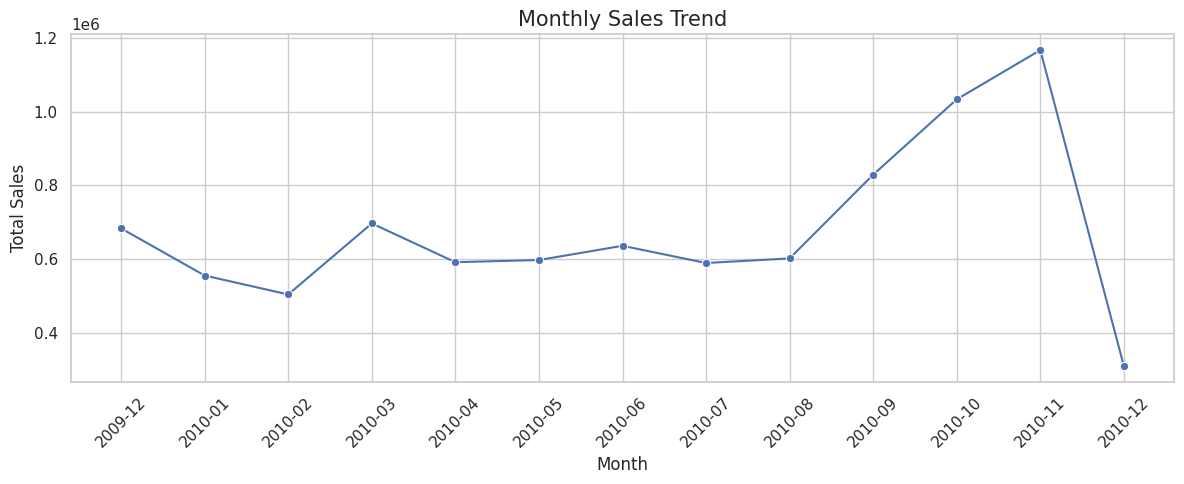

,Month,TotalAmount
0,2009-12,683504.010
1,2010-01,555802.672
2,2010-02,504558.956
3,2010-03,696978.471
4,2010-04,591982.002
5,2010-05,597833.380
6,2010-06,636371.130
7,2010-07,589736.170
8,2010-08,602224.600
9,2010-09,829013.951


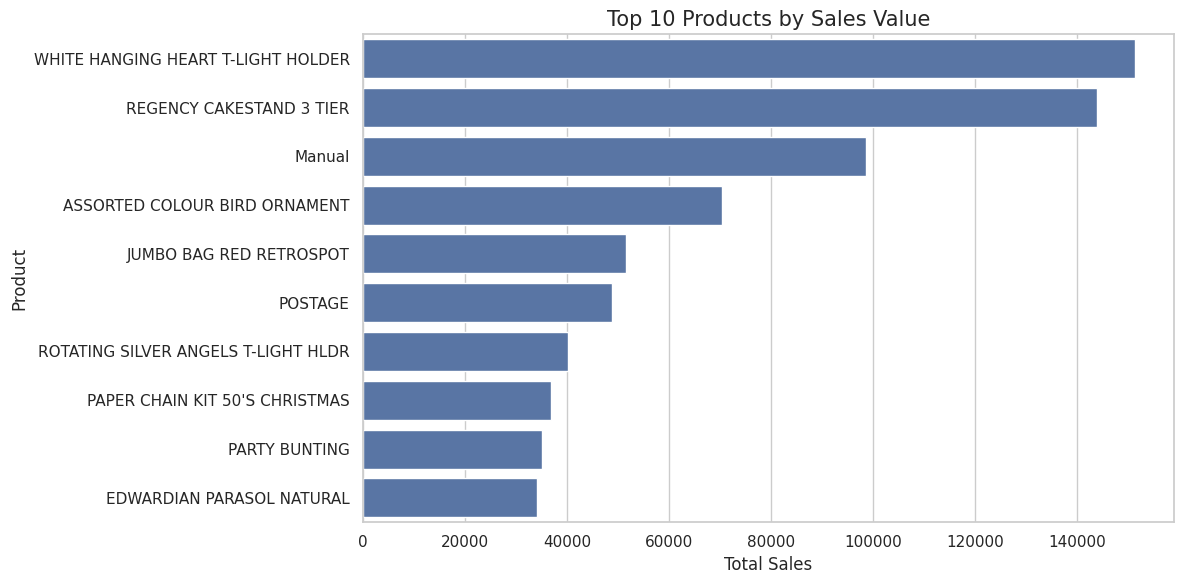

,Description,TotalAmount
4222,WHITE HANGING HEART T-LIGHT HOLDER,151339.16
3214,REGENCY CAKESTAND 3 TIER,143727.60
2412,Manual,98531.99
232,ASSORTED COLOUR BIRD ORNAMENT,70291.03
2034,JUMBO BAG RED RETROSPOT,51644.25
3011,POSTAGE,48741.08
3330,ROTATING SILVER ANGELS T-LIGHT HLDR,40156.05
2631,PAPER CHAIN KIT 50'S CHRISTMAS,36871.55
2645,PARTY BUNTING,35017.30
1267,EDWARDIAN PARASOL NATURAL,34044.75


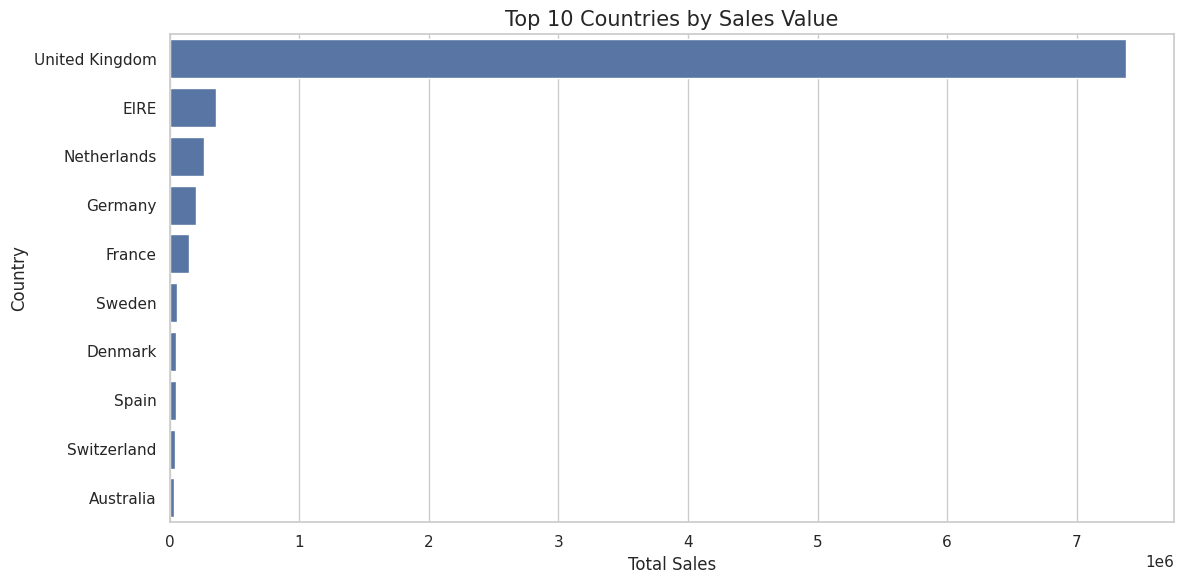

,Country,TotalAmount
34,United Kingdom,7381644.433
9,EIRE,356041.860
21,Netherlands,268784.350
12,Germany,202025.391
11,France,146107.070
29,Sweden,53147.990
8,Denmark,50906.850
28,Spain,47568.650
30,Switzerland,43921.390
0,Australia,31446.800


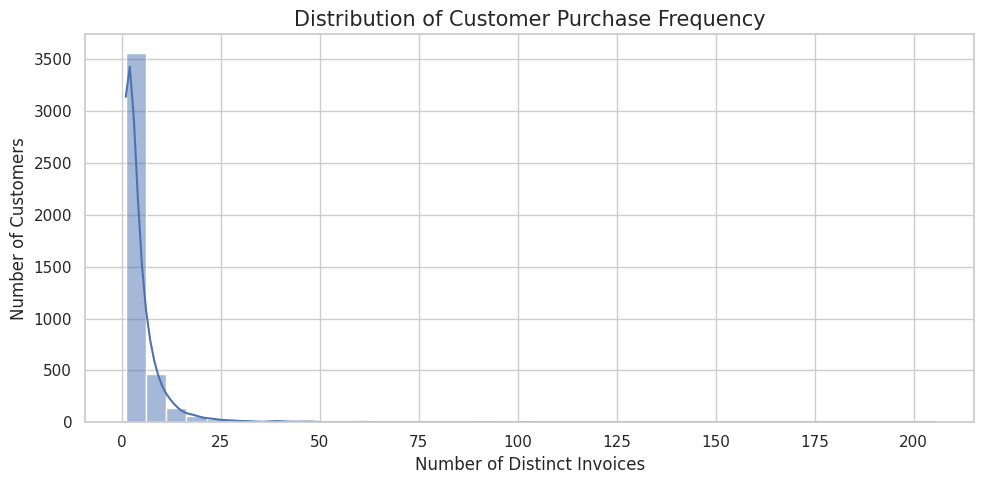

,InvoiceFrequency
count,4312.000000
mean,4.455705
std,8.170213
min,1.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,205.000000


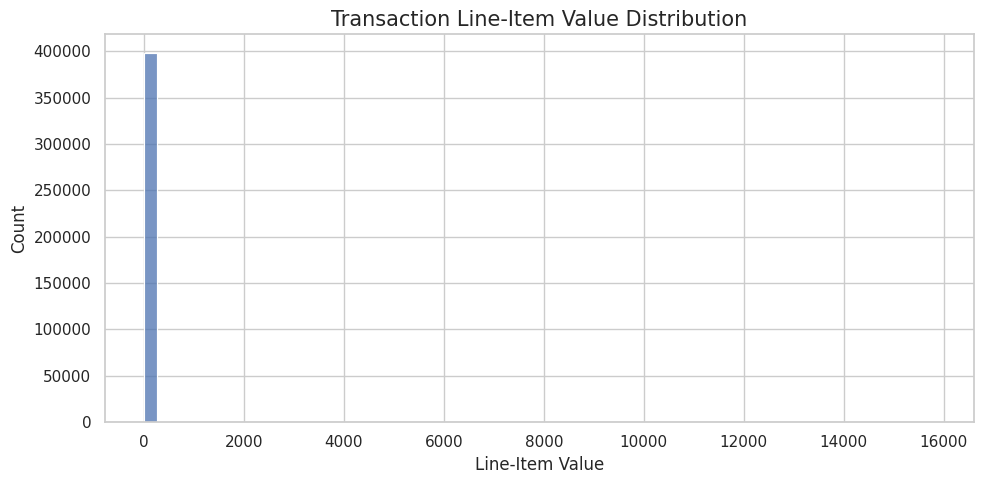

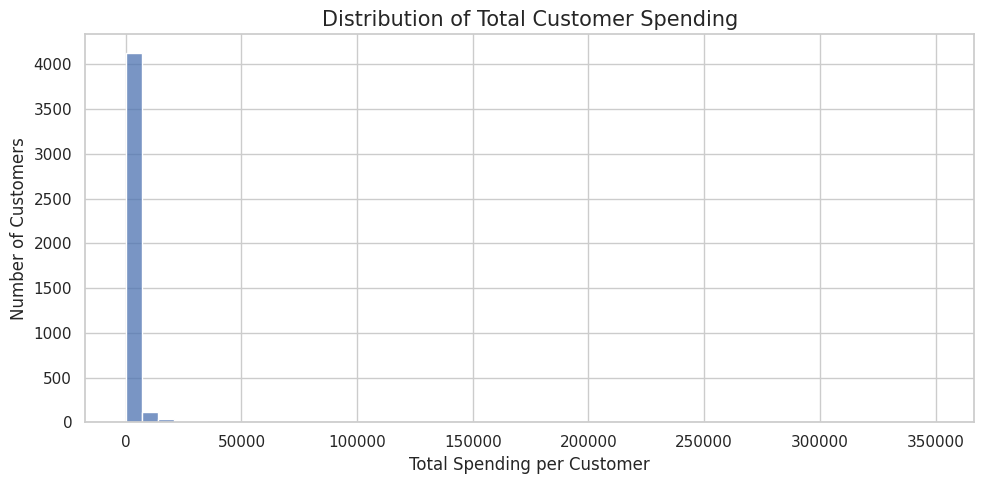

,TotalCustomerSpending
count,4312.000000
mean,2040.406712
std,8911.755977
min,2.950000
25%,307.187500
50%,701.615000
75%,1714.932500
max,349164.350000


EDA completed successfully.


In [7]:

# ============================================================
# CELL 7: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", palette="deep")

# ------------------------------------------------------------
# 1. MONTHLY SALES TREND
# ------------------------------------------------------------

monthly_sales = (
    df_clean.assign(
        Month=df_clean["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month", as_index=False)["TotalAmount"]
    .sum()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="TotalAmount",
    marker="o"
)
plt.title("Monthly Sales Trend", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales)

# ------------------------------------------------------------
# 2. TOP 10 PRODUCTS BY SALES VALUE
# ------------------------------------------------------------

top_products = (
    df_clean.groupby("Description", as_index=False)["TotalAmount"]
    .sum()
    .sort_values("TotalAmount", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_products,
    x="TotalAmount",
    y="Description"
)
plt.title("Top 10 Products by Sales Value", fontsize=15)
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(top_products)

# ------------------------------------------------------------
# 3. TOP 10 COUNTRIES BY SALES VALUE
# ------------------------------------------------------------

top_countries = (
    df_clean.groupby("Country", as_index=False)["TotalAmount"]
    .sum()
    .sort_values("TotalAmount", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_countries,
    x="TotalAmount",
    y="Country"
)
plt.title("Top 10 Countries by Sales Value", fontsize=15)
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(top_countries)

# ------------------------------------------------------------
# 4. CUSTOMER PURCHASE FREQUENCY
# Number of distinct invoices per customer
# ------------------------------------------------------------

customer_frequency = (
    df_clean.groupby("Customer ID")["Invoice"]
    .nunique()
    .reset_index(name="InvoiceFrequency")
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=customer_frequency,
    x="InvoiceFrequency",
    bins=40,
    kde=True
)
plt.title("Distribution of Customer Purchase Frequency", fontsize=15)
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

display(customer_frequency["InvoiceFrequency"].describe())

# ------------------------------------------------------------
# 5. TRANSACTION VALUE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x="TotalAmount",
    bins=60
)
plt.title("Transaction Line-Item Value Distribution", fontsize=15)
plt.xlabel("Line-Item Value")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CUSTOMER SPENDING DISTRIBUTION
# ------------------------------------------------------------

customer_spending = (
    df_clean.groupby("Customer ID")["TotalAmount"]
    .sum()
    .reset_index(name="TotalCustomerSpending")
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=customer_spending,
    x="TotalCustomerSpending",
    bins=50
)
plt.title("Distribution of Total Customer Spending", fontsize=15)
plt.xlabel("Total Spending per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

display(customer_spending["TotalCustomerSpending"].describe())

print("EDA completed successfully.")


In [8]:

# ============================================================
# CELL 8: RFM FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("RFM FEATURE ENGINEERING")
print("=" * 65)

# 1. Define the reference date:
# One day after the last transaction in the dataset.
# This makes the most recent customer's Recency equal to 1 day.

snapshot_date = df_clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

print(f"\nRFM Reference Date: {snapshot_date.date()}")

# 2. Calculate RFM metrics for each customer

rfm = (
    df_clean.groupby("Customer ID")
    .agg(
        Recency=("InvoiceDate", lambda dates:
                 (snapshot_date - dates.max().normalize()).days),
        Frequency=("Invoice", "nunique"),
        Monetary=("TotalAmount", "sum")
    )
    .reset_index()
)

# 3. Display the RFM dataset

print("\n--- First 10 Customer RFM Records ---")
display(rfm.head(10))

# 4. Validate the generated features

print("\n--- RFM Dataset Information ---")
print(f"Number of customers: {len(rfm):,}")
print(f"Number of columns: {rfm.shape[1]}")
print(f"Missing values: {rfm.isnull().sum().sum():,}")
print(f"Duplicate customer IDs: {rfm['Customer ID'].duplicated().sum():,}")

print("\n--- RFM Statistical Summary ---")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)

# 5. Check for invalid values

print("\n--- RFM Validity Checks ---")
print(f"Recency <= 0: {(rfm['Recency'] <= 0).sum():,}")
print(f"Frequency <= 0: {(rfm['Frequency'] <= 0).sum():,}")
print(f"Monetary <= 0: {(rfm['Monetary'] <= 0).sum():,}")

# 6. Show the top 10 customers by monetary value

print("\n--- Top 10 Customers by Total Spending ---")
display(
    rfm.sort_values("Monetary", ascending=False).head(10)
)

print("\nRFM feature engineering completed successfully.")


RFM FEATURE ENGINEERING

RFM Reference Date: 2010-12-10

--- First 10 Customer RFM Records ---


,Customer ID,Recency,Frequency,Monetary
0,12346,165,11,372.86
1,12347,3,2,1323.32
2,12348,74,1,222.16
3,12349,43,3,2671.14
4,12351,11,1,300.93
5,12352,11,2,343.80
6,12353,44,1,317.76
7,12355,203,1,488.21
8,12356,16,3,3560.30
9,12357,24,2,12079.99



--- RFM Dataset Information ---
Number of customers: 4,312
Number of columns: 4
Missing values: 0
Duplicate customer IDs: 0

--- RFM Statistical Summary ---


,count,mean,std,min,25%,50%,75%,max
Recency,4312.0,91.172542,96.861457,1.00,18.0000,53.000,136.0000,374.00
Frequency,4312.0,4.455705,8.170213,1.00,1.0000,2.000,5.0000,205.00
Monetary,4312.0,2040.406712,8911.755977,2.95,307.1875,701.615,1714.9325,349164.35



--- RFM Validity Checks ---
Recency <= 0: 0
Frequency <= 0: 0
Monetary <= 0: 0

--- Top 10 Customers by Total Spending ---


,Customer ID,Recency,Frequency,Monetary
4183,18102,1,89,349164.35
1637,14646,10,78,248396.50
1269,14156,7,102,196549.74
1840,14911,1,205,152121.22
939,13694,9,94,131443.19
3744,17511,3,31,84541.17
1951,15061,3,86,83284.38
3128,16684,15,27,80489.21
3177,16754,8,29,65500.07
4065,17949,7,74,60117.60



RFM feature engineering completed successfully.


RFM SKEWNESS ANALYSIS


,Skewness
Recency,1.282904
Frequency,10.546821
Monetary,24.000183


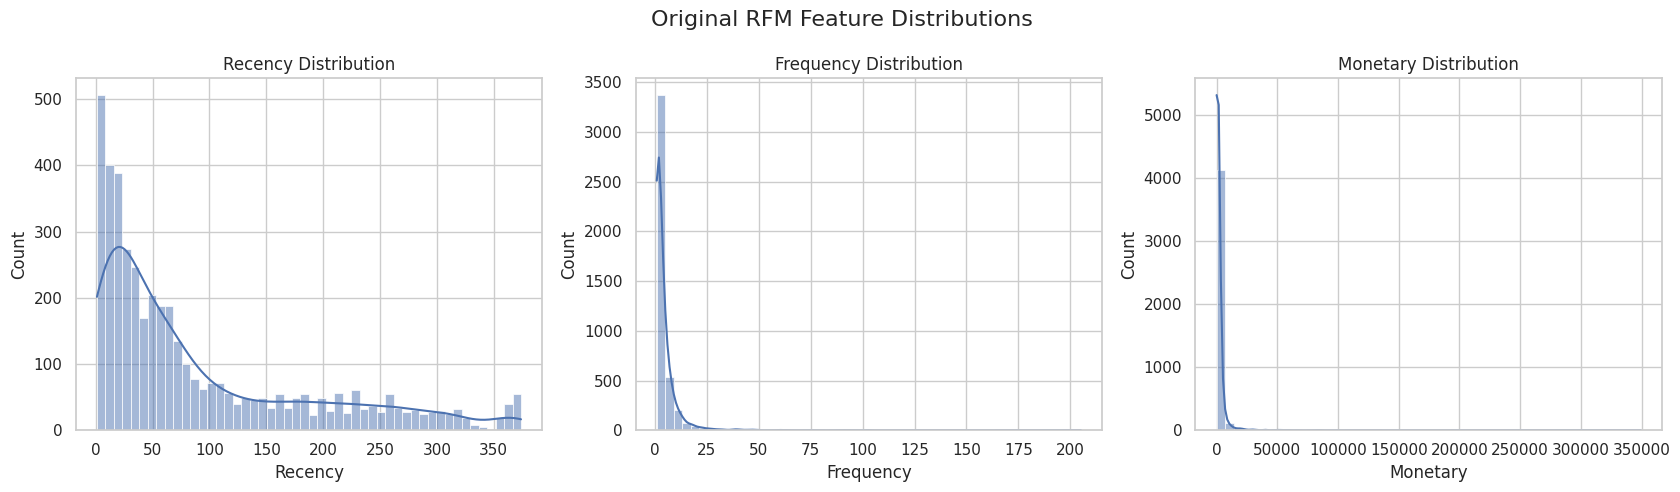


--- Skewness After log1p Transformation ---


,Skewness After log1p
Recency,-0.425008
Frequency,1.181715
Monetary,0.265846


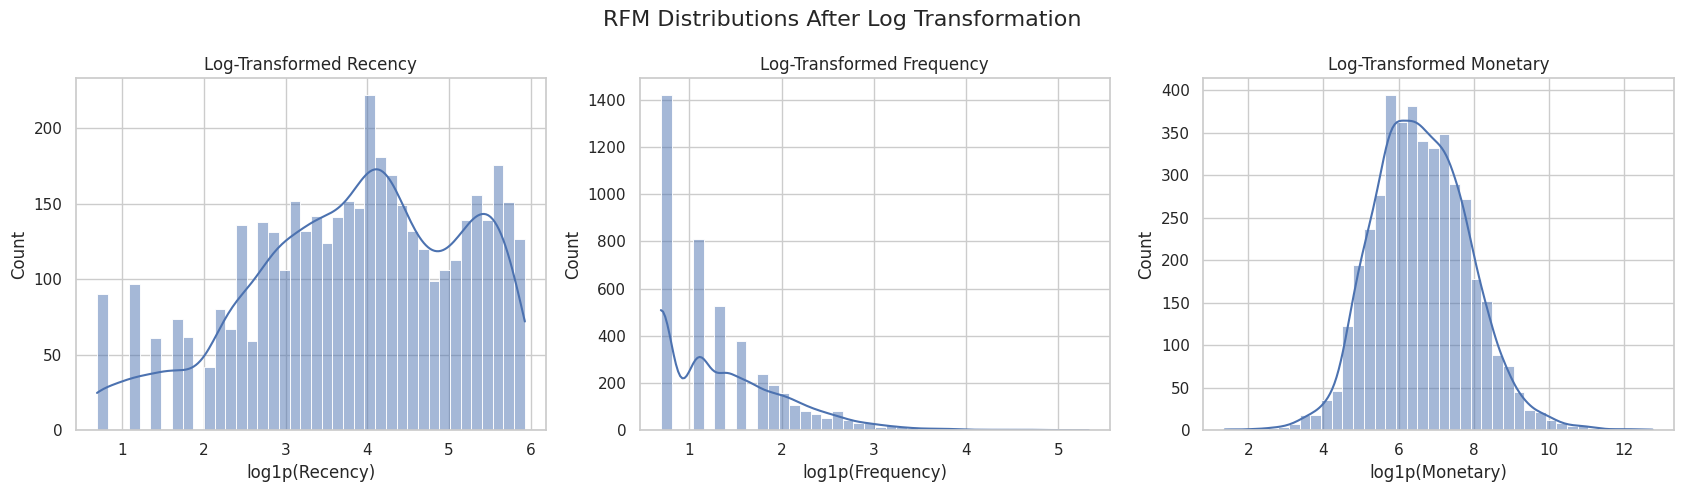


RFM distribution analysis completed.


In [9]:

# ============================================================
# CELL 9: RFM DISTRIBUTION AND SKEWNESS ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

rfm_features = ["Recency", "Frequency", "Monetary"]

# 1. Display skewness
print("=" * 65)
print("RFM SKEWNESS ANALYSIS")
print("=" * 65)

skewness = rfm[rfm_features].skew()

display(
    skewness.rename("Skewness").to_frame()
)

# 2. Plot original distributions
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, rfm_features):
    sns.histplot(
        data=rfm,
        x=feature,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)

plt.suptitle("Original RFM Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# 3. Create log-transformed copies for comparison
# log1p(x) = log(1 + x); suitable for these positive values.

rfm_log = rfm[rfm_features].copy()
rfm_log = np.log1p(rfm_log)

print("\n--- Skewness After log1p Transformation ---")

display(
    rfm_log.skew()
    .rename("Skewness After log1p")
    .to_frame()
)

# 4. Plot transformed distributions
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, rfm_features):
    sns.histplot(
        x=rfm_log[feature],
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Log-Transformed {feature}")
    ax.set_xlabel(f"log1p({feature})")

plt.suptitle("RFM Distributions After Log Transformation", fontsize=16)
plt.tight_layout()
plt.show()

print("\nRFM distribution analysis completed.")


In [10]:

# ============================================================
# CELL 10: LOG TRANSFORMATION AND FEATURE SCALING
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("=" * 65)
print("RFM TRANSFORMATION AND SCALING")
print("=" * 65)

# 1. Select the RFM features
rfm_features = ["Recency", "Frequency", "Monetary"]

# 2. Apply log1p transformation
# Keep the original rfm DataFrame unchanged.
rfm_log = np.log1p(rfm[rfm_features].copy())

print("\n--- Log-Transformed RFM Preview ---")
display(rfm_log.head())

# 3. Standardize the transformed features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to DataFrame for easy inspection
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=rfm_features,
    index=rfm.index
)

print("\n--- Scaled RFM Preview ---")
display(rfm_scaled_df.head())

# 4. Validate scaled features
print("\n--- Scaled Feature Statistics ---")
display(
    pd.DataFrame({
        "Mean": rfm_scaled_df.mean(),
        "Standard Deviation": rfm_scaled_df.std(ddof=0),
        "Minimum": rfm_scaled_df.min(),
        "Maximum": rfm_scaled_df.max()
    })
)

print("\nNumber of customers:", len(rfm_scaled_df))
print("Missing scaled values:", rfm_scaled_df.isnull().sum().sum())
print("Infinite scaled values:", np.isinf(rfm_scaled_df.to_numpy()).sum())

print("\nRFM scaling completed successfully.")


RFM TRANSFORMATION AND SCALING

--- Log-Transformed RFM Preview ---


,Recency,Frequency,Monetary
0,5.111988,2.484907,5.923881
1,1.386294,1.098612,7.188654
2,4.317488,0.693147,5.407889
3,3.784190,1.386294,7.890635
4,2.484907,0.693147,5.710195



--- Scaled RFM Preview ---


,Recency,Frequency,Monetary
0,0.966257,1.613017,-0.534787
1,-1.900162,-0.394693,0.452542
2,0.354996,-0.981910,-0.937590
3,-0.055305,0.021945,1.000535
4,-1.054928,-0.981910,-0.701598



--- Scaled Feature Statistics ---


,Mean,Standard Deviation,Minimum,Maximum
Recency,2.587087e-16,1.0,-2.433445,1.593242
Frequency,-2.595327e-17,1.0,-0.981910,5.730367
Monetary,2.306957e-16,1.0,-4.086817,4.804321



Number of customers: 4312
Missing scaled values: 0
Infinite scaled values: 0

RFM scaling completed successfully.


OPTIMAL NUMBER OF CLUSTERS
K =  2 | Inertia = 6,605.32 | Silhouette Score = 0.4248
K =  3 | Inertia = 4,973.78 | Silhouette Score = 0.3330
K =  4 | Inertia = 3,977.40 | Silhouette Score = 0.3296
K =  5 | Inertia = 3,347.93 | Silhouette Score = 0.3203
K =  6 | Inertia = 2,925.02 | Silhouette Score = 0.3113
K =  7 | Inertia = 2,612.14 | Silhouette Score = 0.3092
K =  8 | Inertia = 2,396.96 | Silhouette Score = 0.2769
K =  9 | Inertia = 2,212.56 | Silhouette Score = 0.2767
K = 10 | Inertia = 2,042.60 | Silhouette Score = 0.2819

--- Evaluation Summary ---


,K,Inertia,Silhouette Score
0,2,6605.320419,0.424794
1,3,4973.781946,0.333017
2,4,3977.396711,0.329639
3,5,3347.933750,0.320320
4,6,2925.020606,0.311346
5,7,2612.143966,0.309194
6,8,2396.963830,0.276910
7,9,2212.557754,0.276656
8,10,2042.596665,0.281854


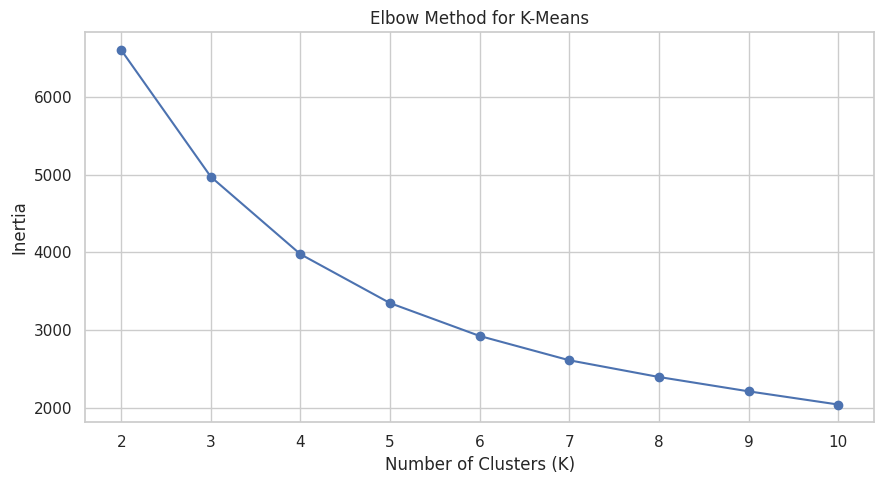

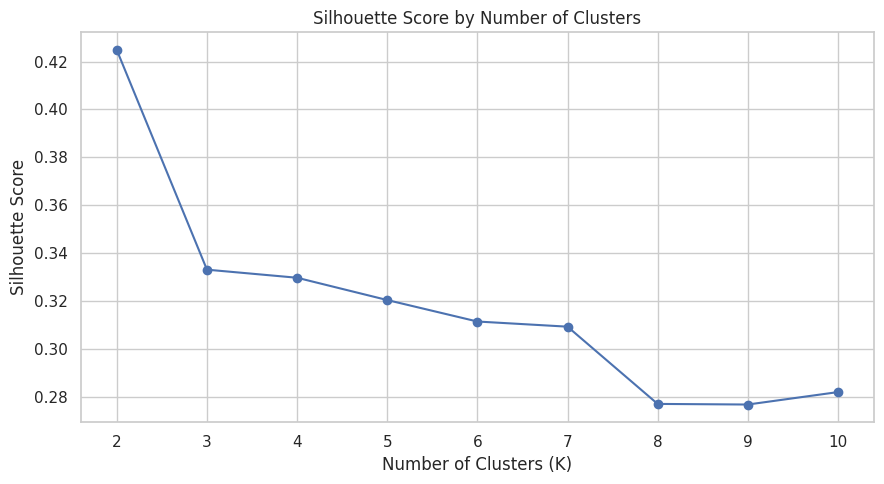


Highest sampled silhouette score: K = 2, Score = 0.4248

Cluster-count evaluation completed.


In [11]:

# ============================================================
# CELL 11: OPTIMAL K SELECTION
# Elbow Method + Silhouette Score
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("=" * 65)
print("OPTIMAL NUMBER OF CLUSTERS")
print("=" * 65)

# Candidate cluster counts
k_values = range(2, 11)

inertias = []
silhouette_scores = []

# Evaluate each candidate K
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled_df)

    inertias.append(kmeans.inertia_)

    score = silhouette_score(
        rfm_scaled_df,
        labels,
        sample_size=min(2000, len(rfm_scaled_df)),
        random_state=42
    )
    silhouette_scores.append(score)

    print(
        f"K = {k:2d} | "
        f"Inertia = {kmeans.inertia_:,.2f} | "
        f"Silhouette Score = {score:.4f}"
    )

# Store the results
k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

print("\n--- Evaluation Summary ---")
display(k_results)

# Plot 1: Elbow method
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Plot 2: Silhouette scores
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Highest sampled silhouette score
best_silhouette_row = k_results.loc[
    k_results["Silhouette Score"].idxmax()
]

print(
    f"\nHighest sampled silhouette score: "
    f"K = {int(best_silhouette_row['K'])}, "
    f"Score = {best_silhouette_row['Silhouette Score']:.4f}"
)

print("\nCluster-count evaluation completed.")


In [12]:

# ============================================================
# CELL 12: COMPARE K = 2, 3, AND 4
# ============================================================

import pandas as pd
from sklearn.cluster import KMeans

print("=" * 65)
print("COMPARING CANDIDATE CLUSTER SOLUTIONS")
print("=" * 65)

candidate_ks = [2, 3, 4]
cluster_comparisons = {}

for k in candidate_ks:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(rfm_scaled_df)

    # Copy the original customer-level RFM values
    comparison_df = rfm[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ].copy()

    comparison_df["Cluster"] = labels

    # Cluster sizes
    sizes = (
        comparison_df["Cluster"]
        .value_counts()
        .sort_index()
        .rename("Customers")
        .to_frame()
    )

    sizes["Percentage"] = (
        sizes["Customers"] / len(comparison_df) * 100
    )

    # Average original RFM values per cluster
    profiles = (
        comparison_df.groupby("Cluster")[
            ["Recency", "Frequency", "Monetary"]
        ]
        .mean()
        .round(2)
    )

    # Median values help reduce the influence of extreme customers
    medians = (
        comparison_df.groupby("Cluster")[
            ["Recency", "Frequency", "Monetary"]
        ]
        .median()
        .round(2)
    )

    cluster_comparisons[k] = {
        "labels": labels,
        "sizes": sizes,
        "profiles": profiles,
        "medians": medians
    }

    print(f"\n{'=' * 25} K = {k} {'=' * 25}")

    print("\nCluster sizes:")
    display(sizes)

    print("\nMean RFM profile:")
    display(profiles)

    print("\nMedian RFM profile:")
    display(medians)

print("\nCandidate cluster comparison completed.")


COMPARING CANDIDATE CLUSTER SOLUTIONS

========================= K = 2 =========================

Cluster sizes:


,Customers,Percentage
Cluster,,
0,2670,61.920223
1,1642,38.079777



Mean RFM profile:


,Recency,Frequency,Monetary
Cluster,,,
0,128.99,1.73,517.66
1,29.68,8.88,4516.50



Median RFM profile:


...


Mean RFM profile:


,Recency,Frequency,Monetary
Cluster,,,
0,23.95,1.97,532.08
1,13.83,13.56,7381.58
2,190.57,1.30,305.66
3,80.21,4.14,1759.99



Median RFM profile:


,Recency,Frequency,Monetary
Cluster,,,
0,21.0,2.0,457.70
1,9.5,9.0,3416.26
2,187.0,1.0,258.58
3,64.0,4.0,1361.96



Candidate cluster comparison completed.


FINAL CUSTOMER SEGMENTATION MODEL

Selected K: 3
Number of customers: 4,312
Silhouette score (sampled): 0.3326

--- Final Cluster Sizes ---


,Customers,Percentage
Cluster,,
0,1760,40.82
1,815,18.90
2,1737,40.28



--- Final Cluster Profiles ---


,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary
Cluster,,,,,,,
0,1760,54.11,38.0,3.42,3.0,1288.47,981.64
1,815,18.14,10.0,13.41,9.0,7324.09,3472.61
2,1737,162.99,156.0,1.31,1.0,323.20,262.32


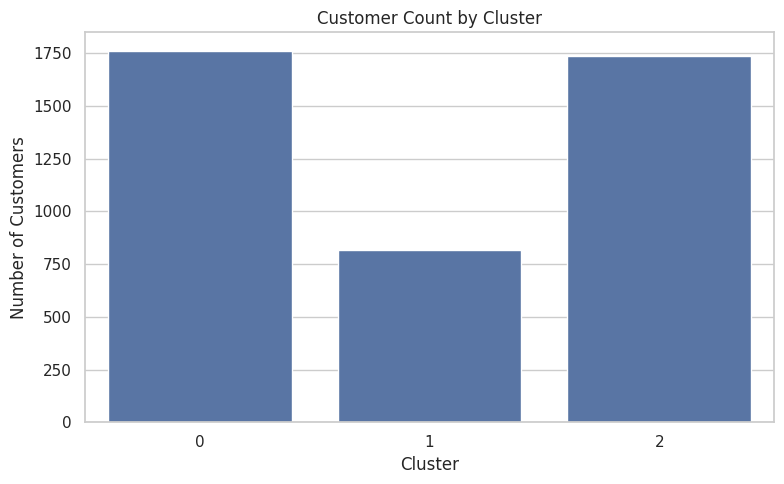


Final K-Means clustering completed.


In [13]:

# ============================================================
# CELL 13: FINAL K-MEANS MODEL (K = 3)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("=" * 65)
print("FINAL CUSTOMER SEGMENTATION MODEL")
print("=" * 65)

# 1. Set the selected number of clusters
FINAL_K = 3

# 2. Train the final model on scaled log-RFM features
final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20
)

final_labels = final_kmeans.fit_predict(rfm_scaled_df)

# 3. Add cluster labels to the original RFM records
rfm_segmented = rfm.copy()
rfm_segmented["Cluster"] = final_labels

# 4. Calculate final silhouette score
final_silhouette = silhouette_score(
    rfm_scaled_df,
    final_labels,
    sample_size=min(2000, len(rfm_scaled_df)),
    random_state=42
)

print(f"\nSelected K: {FINAL_K}")
print(f"Number of customers: {len(rfm_segmented):,}")
print(f"Silhouette score (sampled): {final_silhouette:.4f}")

# 5. Cluster size and percentage
cluster_sizes = (
    rfm_segmented["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)

cluster_sizes["Percentage"] = (
    cluster_sizes["Customers"]
    / len(rfm_segmented) * 100
).round(2)

print("\n--- Final Cluster Sizes ---")
display(cluster_sizes)

# 6. Cluster profiles using original RFM values
cluster_profiles = (
    rfm_segmented.groupby("Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median")
    )
    .round(2)
)

print("\n--- Final Cluster Profiles ---")
display(cluster_profiles)

# 7. Visualize cluster sizes
plt.figure(figsize=(8, 5))
sns.countplot(
    data=rfm_segmented,
    x="Cluster",
    order=sorted(rfm_segmented["Cluster"].unique())
)
plt.title("Customer Count by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\nFinal K-Means clustering completed.")


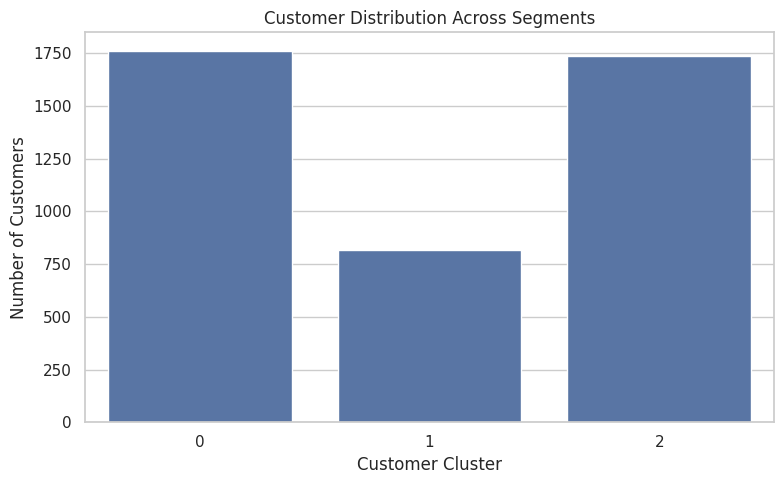

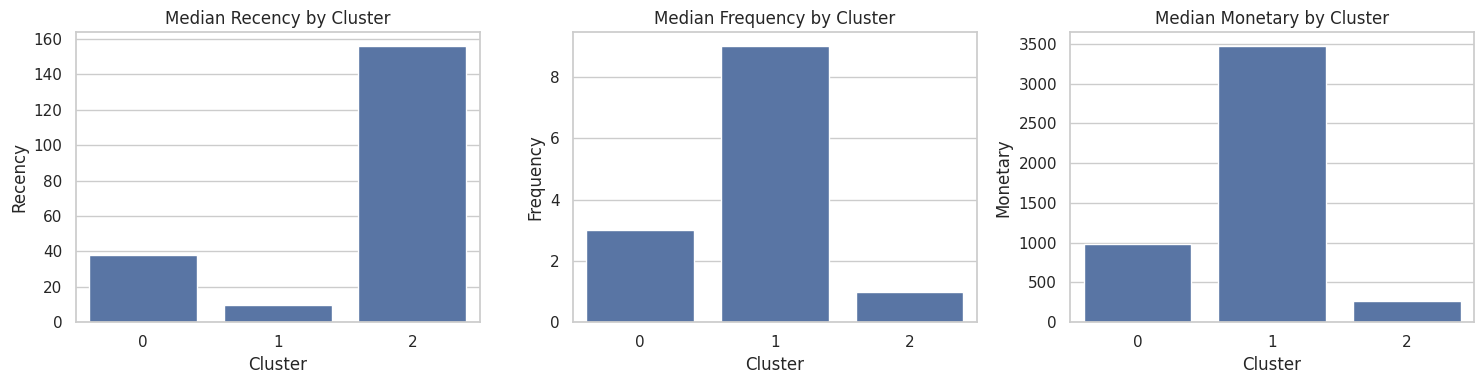

Saved customer_segments.csv
Saved customer_segment_profiles.csv


In [14]:

# CELL 14: Visualize and save customer segmentation results

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualize customer distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=rfm_segmented, x="Cluster")
plt.title("Customer Distribution Across Segments")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 2. Visualize RFM cluster profiles using medians
median_profiles = (
    rfm_segmented.groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, median_profiles.columns):
    sns.barplot(
        x=median_profiles.index,
        y=median_profiles[feature],
        ax=ax
    )
    ax.set_title(f"Median {feature} by Cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

# 3. Export customer-level segments
rfm_segmented.to_csv(
    "customer_segments.csv",
    index=False
)

# 4. Export cluster profiles
cluster_profiles.to_csv(
    "customer_segment_profiles.csv"
)

print("Saved customer_segments.csv")
print("Saved customer_segment_profiles.csv")


In [15]:

# CELL 15: Evaluate final clustering quality

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd

X = rfm_scaled_df
labels = rfm_segmented["Cluster"]

# Calculate clustering evaluation metrics
evaluation_results = {
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ],
    "Score": [
        silhouette_score(
            X,
            labels,
            sample_size=min(2000, len(X)),
            random_state=42
        ),
        davies_bouldin_score(X, labels),
        calinski_harabasz_score(X, labels)
    ],
    "Interpretation": [
        "Higher is generally better; range -1 to 1",
        "Lower is generally better",
        "Higher is generally better"
    ]
}

evaluation_df = pd.DataFrame(evaluation_results)

print("=" * 65)
print("CUSTOMER SEGMENTATION — EVALUATION RESULTS")
print("=" * 65)
print(evaluation_df.to_string(index=False))

# Save evaluation metrics
evaluation_df.to_csv("clustering_evaluation.csv", index=False)

print("\nSaved clustering_evaluation.csv")


CUSTOMER SEGMENTATION — EVALUATION RESULTS
                 Metric       Score                            Interpretation
       Silhouette Score    0.332617 Higher is generally better; range -1 to 1
   Davies-Bouldin Index    1.066801                 Lower is generally better
Calinski-Harabasz Index 3449.170197                Higher is generally better

Saved clustering_evaluation.csv


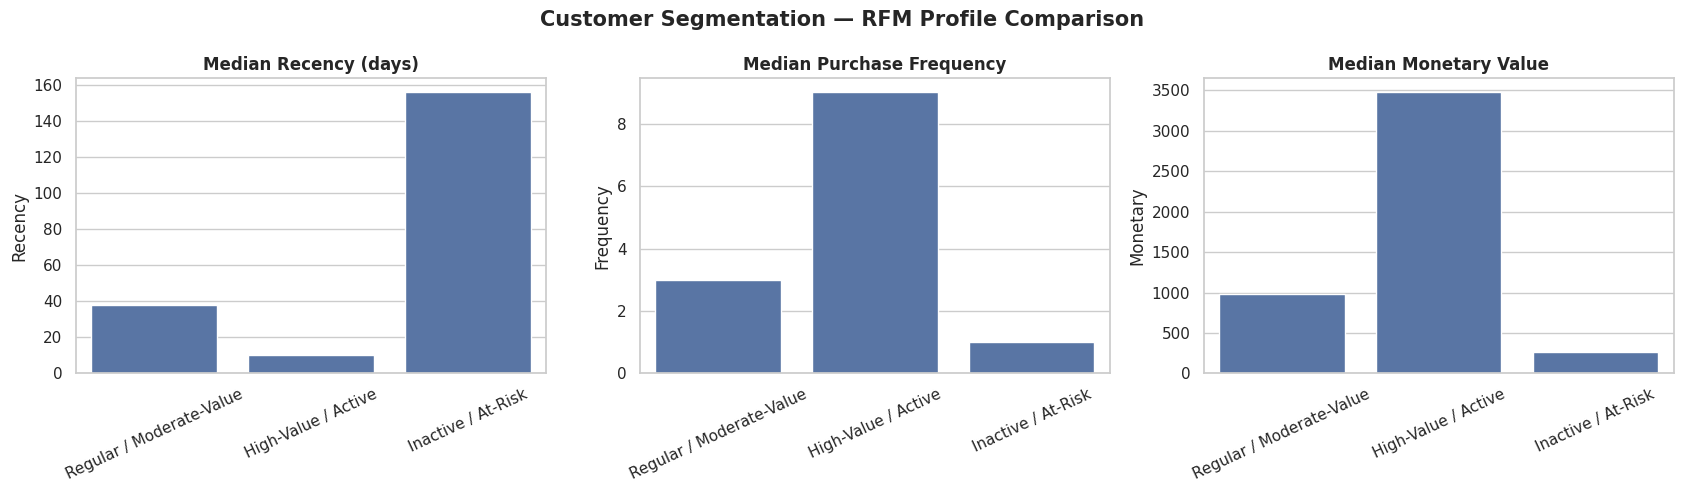

Final segment comparison:
 Cluster  Customers  Recency  Frequency  Monetary                  Segment
       0       1760     38.0        3.0   981.645 Regular / Moderate-Value
       1        815     10.0        9.0  3472.610      High-Value / Active
       2       1737    156.0        1.0   262.320       Inactive / At-Risk


In [16]:

# CELL 16: Final Business-Oriented Segment Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare median RFM values for robust comparison
plot_data = (
    rfm_segmented.groupby("Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Recency=("Recency", "median"),
        Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median")
    )
    .reset_index()
)

segment_names = {
    0: "Regular / Moderate-Value",
    1: "High-Value / Active",
    2: "Inactive / At-Risk"
}

plot_data["Segment"] = plot_data["Cluster"].map(segment_names)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("Recency", "Median Recency (days)"),
    ("Frequency", "Median Purchase Frequency"),
    ("Monetary", "Median Monetary Value")
]

for ax, (column, title) in zip(axes, metrics):
    sns.barplot(
        data=plot_data,
        x="Segment",
        y=column,
        ax=ax
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

plt.suptitle(
    "Customer Segmentation — RFM Profile Comparison",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

print("Final segment comparison:")
print(plot_data.to_string(index=False))


In [17]:

# CELL 17: Export final project summary

import pandas as pd

final_summary = pd.DataFrame({
    "Cluster": [0, 1, 2],
    "Segment": [
        "Regular / Moderate-Value",
        "High-Value / Active",
        "Inactive / At-Risk"
    ],
    "Customers": [1760, 815, 1737],
    "Percentage": [40.82, 18.90, 40.28],
    "Median_Recency_Days": [38.0, 10.0, 156.0],
    "Median_Frequency": [3.0, 9.0, 1.0],
    "Median_Monetary": [981.645, 3472.610, 262.320]
})

final_summary.to_csv(
    "final_customer_segmentation_summary.csv",
    index=False
)

print("FINAL CUSTOMER SEGMENTATION SUMMARY")
print("=" * 60)
print(final_summary.to_string(index=False))
print("\nSaved: final_customer_segmentation_summary.csv")


FINAL CUSTOMER SEGMENTATION SUMMARY
 Cluster                  Segment  Customers  Percentage  Median_Recency_Days  Median_Frequency  Median_Monetary
       0 Regular / Moderate-Value       1760       40.82                 38.0               3.0          981.645
       1      High-Value / Active        815       18.90                 10.0               9.0         3472.610
       2       Inactive / At-Risk       1737       40.28                156.0               1.0          262.320

Saved: final_customer_segmentation_summary.csv
